# Sentiment Analysis using Machine Learning

## Objective

The objective of this project is to build a machine learning model that classifies text into three sentiment categories:

- Positive
- Negative
- Neutral

## Technologies Used

- Python
- Pandas
- NumPy
- NLTK
- Scikit-learn
- Matplotlib
- Seaborn
- WordCloud
- Jupyter Notebook

## Machine Learning Models

1. Naive Bayes
2. Logistic Regression

In [1]:
import pandas as pd
import numpy as np
import re
import nltk
import matplotlib.pyplot as plt
import seaborn as sns

from wordcloud import WordCloud

from nltk.corpus import stopwords
from nltk.tokenize import word_tokenize
from nltk.stem import WordNetLemmatizer

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer

from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

print("Libraries imported successfully!")

Libraries imported successfully!


In [2]:
nltk.download('stopwords')
nltk.download('punkt')
nltk.download('punkt_tab')
nltk.download('wordnet')
nltk.download('omw-1.4')

print("NLTK resources downloaded successfully!")

[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\HP\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package punkt to
[nltk_data]     C:\Users\HP\AppData\Roaming\nltk_data...
[nltk_data]   Unzipping tokenizers\punkt.zip.
[nltk_data] Downloading package punkt_tab to
[nltk_data]     C:\Users\HP\AppData\Roaming\nltk_data...
[nltk_data]   Unzipping tokenizers\punkt_tab.zip.
[nltk_data] Downloading package wordnet to
[nltk_data]     C:\Users\HP\AppData\Roaming\nltk_data...
[nltk_data] Error downloading 'wordnet' from
[nltk_data]     <https://raw.githubusercontent.com/nltk/nltk_data/gh-
[nltk_data]     pages/packages/corpora/wordnet.zip>:   [WinError
[nltk_data]     10054] An existing connection was forcibly closed by
[nltk_data]     the remote host
[nltk_data] Downloading package omw-1.4 to
[nltk_data]     C:\Users\HP\AppData\Roaming\nltk_data...


NLTK resources downloaded successfully!


[nltk_data] Error downloading 'omw-1.4' from
[nltk_data]     <https://raw.githubusercontent.com/nltk/nltk_data/gh-
[nltk_data]     pages/packages/corpora/omw-1.4.zip>:   <urlopen error
[nltk_data]     pathsec.urlopen: no validated address for host
[nltk_data]     'raw.githubusercontent.com'; refusing to connect by
[nltk_data]     unvalidated hostname>


In [1]:
df = pd.read_csv("Tweets.csv")

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

display(df.head())

NameError: name 'pd' is not defined

In [2]:
import pandas as pd
import numpy as np
import re
import nltk
import matplotlib.pyplot as plt
import seaborn as sns

from wordcloud import WordCloud

from nltk.corpus import stopwords
from nltk.tokenize import word_tokenize

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer

from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

print("Libraries imported successfully!")

Libraries imported successfully!


In [4]:
df = pd.read_csv(r"C:\Users\HP\Music\Tweets.csv")

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

display(df.head())

PermissionError: [Errno 13] Permission denied: 'C:\\Users\\HP\\Music\\Tweets.csv'

In [1]:
import pandas as pd
import numpy as np
import re
import nltk

In [2]:
import nltk

# Check/download only the resources needed
for resource in ['stopwords', 'punkt', 'punkt_tab', 'wordnet']:
    try:
        nltk.data.find(resource)
        print(resource, "already available")
    except:
        print(resource, "needs to be downloaded")

stopwords needs to be downloaded
punkt needs to be downloaded
punkt_tab needs to be downloaded
wordnet needs to be downloaded


In [3]:
import nltk

resources = {
    "stopwords": "corpora/stopwords",
    "punkt": "tokenizers/punkt",
    "punkt_tab": "tokenizers/punkt_tab",
    "wordnet": "corpora/wordnet"
}

for name, path in resources.items():
    try:
        nltk.data.find(path)
        print(name, "AVAILABLE")
    except LookupError:
        print(name, "NOT AVAILABLE")

stopwords AVAILABLE
punkt AVAILABLE
punkt_tab AVAILABLE
wordnet NOT AVAILABLE


In [4]:
import os

print("Current folder:")
print(os.getcwd())

print("\nFiles in this folder:")
print(os.listdir())

Current folder:
C:\Users\HP\OneDrive\Desktop\Sentiment_Analysis_Project

Files in this folder:
['.git', '.ipynb_checkpoints', 'sentiment_analysis_dataset.csv', 'Sentiment_Analysis_Project.ipynb', 'Sentiment_Analysis_Task4_Final.ipynb.ipynb', 'sentiment_model.pkl', 'tfidf_vectorizer.pkl', 'Tweets.csv']


In [5]:
df = pd.read_csv("Tweets.csv")

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

display(df.head())

PermissionError: [Errno 13] Permission denied: 'Tweets.csv'

In [6]:
import os

print("Is Tweets.csv a file?", os.path.isfile("Tweets.csv"))
print("Is Tweets.csv a folder?", os.path.isdir("Tweets.csv"))

Is Tweets.csv a file? False
Is Tweets.csv a folder? True


In [7]:
df = pd.read_csv("Tweets.csv")

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

display(df.head())

Dataset loaded successfully!
Dataset shape: (14640, 15)


,tweet_id,airline_sentiment,airline_sentiment_confidence,negativereason,negativereason_confidence,airline,airline_sentiment_gold,name,negativereason_gold,retweet_count,text,tweet_coord,tweet_created,tweet_location,user_timezone
0,570306133677760513,neutral,1.0000,NaN,NaN,Virgin America,NaN,cairdin,NaN,0,@VirginAmerica What @dhepburn said.,NaN,2015-02-24 11:35:52 -0800,NaN,Eastern Time (US & Canada)
1,570301130888122368,positive,0.3486,NaN,0.0000,Virgin America,NaN,jnardino,NaN,0,@VirginAmerica plus you've added commercials t...,NaN,2015-02-24 11:15:59 -0800,NaN,Pacific Time (US & Canada)
2,570301083672813571,neutral,0.6837,NaN,NaN,Virgin America,NaN,yvonnalynn,NaN,0,@VirginAmerica I didn't today... Must mean I n...,NaN,2015-02-24 11:15:48 -0800,Lets Play,Central Time (US & Canada)
3,570301031407624196,negative,1.0000,Bad Flight,0.7033,Virgin America,NaN,jnardino,NaN,0,@VirginAmerica it's really aggressive to blast...,NaN,2015-02-24 11:15:36 -0800,NaN,Pacific Time (US & Canada)
4,570300817074462722,negative,1.0000,Can't Tell,1.0000,Virgin America,NaN,jnardino,NaN,0,@VirginAmerica and it's a really big bad thing...,NaN,2015-02-24 11:14:45 -0800,NaN,Pacific Time (US & Canada)


In [8]:
df = df[['text', 'airline_sentiment']]

df = df.rename(columns={
    'airline_sentiment': 'sentiment'
})

print("Selected columns successfully!")
display(df.head())

Selected columns successfully!


,text,sentiment
0,@VirginAmerica What @dhepburn said.,neutral
1,@VirginAmerica plus you've added commercials t...,positive
2,@VirginAmerica I didn't today... Must mean I n...,neutral
3,@VirginAmerica it's really aggressive to blast...,negative
4,@VirginAmerica and it's a really big bad thing...,negative


In [9]:
print("Dataset shape:", df.shape)

print("\nMissing values:")
print(df.isnull().sum())

print("\nSentiment distribution:")
print(df['sentiment'].value_counts())

Dataset shape: (14640, 2)

Missing values:
text         0
sentiment    0
dtype: int64

Sentiment distribution:
sentiment
negative    9178
neutral     3099
positive    2363
Name: count, dtype: int64


In [10]:
df = df.dropna(subset=['text', 'sentiment'])

print("Dataset shape after removing missing values:", df.shape)

Dataset shape after removing missing values: (14640, 2)


In [11]:
sentiment_counts = df['sentiment'].value_counts()

plt.figure(figsize=(7, 5))
plt.bar(sentiment_counts.index, sentiment_counts.values)

plt.title("Sentiment Distribution")
plt.xlabel("Sentiment")
plt.ylabel("Number of Tweets")

plt.show()

NameError: name 'plt' is not defined

In [12]:
import matplotlib.pyplot as plt

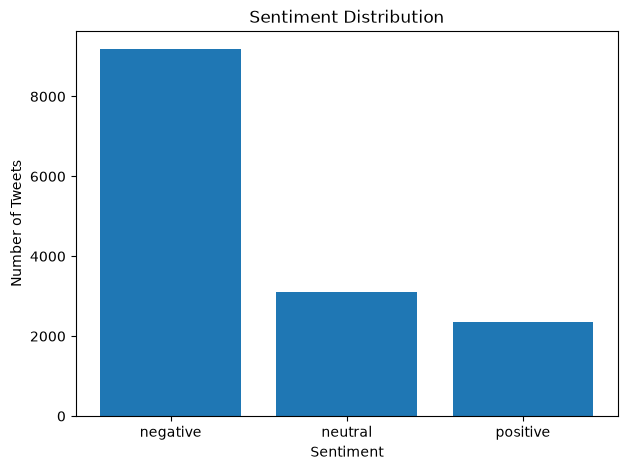

In [13]:
sentiment_counts = df['sentiment'].value_counts()

plt.figure(figsize=(7, 5))
plt.bar(sentiment_counts.index, sentiment_counts.values)

plt.title("Sentiment Distribution")
plt.xlabel("Sentiment")
plt.ylabel("Number of Tweets")

plt.show()

In [14]:
stop_words = set(stopwords.words('english'))

# Keep important negative words
stop_words.discard('not')
stop_words.discard('no')
stop_words.discard('nor')

def preprocess_text(text):
    # Convert to lowercase
    text = text.lower()
    
    # Remove URLs
    text = re.sub(r'http\S+|www\S+', '', text)
    
    # Remove @mentions
    text = re.sub(r'@\w+', '', text)
    
    # Remove hashtag symbol
    text = re.sub(r'#', '', text)
    
    # Remove punctuation and special characters
    text = re.sub(r'[^a-zA-Z\s]', ' ', text)
    
    # Tokenization
    tokens = word_tokenize(text)
    
    # Remove stopwords
    tokens = [word for word in tokens if word not in stop_words]
    
    # Join words back together
    return ' '.join(tokens)

print("Preprocessing function created successfully!")

NameError: name 'stopwords' is not defined

In [15]:
from nltk.corpus import stopwords
from nltk.tokenize import word_tokenize
import re

print("Required NLTK imports loaded successfully!")

Required NLTK imports loaded successfully!


In [16]:
stop_words = set(stopwords.words('english'))

# Keep important negative words
stop_words.discard('not')
stop_words.discard('no')
stop_words.discard('nor')

def preprocess_text(text):
    # Convert to lowercase
    text = text.lower()
    
    # Remove URLs
    text = re.sub(r'http\S+|www\S+', '', text)
    
    # Remove @mentions
    text = re.sub(r'@\w+', '', text)
    
    # Remove hashtag symbol
    text = re.sub(r'#', '', text)
    
    # Remove punctuation and special characters
    text = re.sub(r'[^a-zA-Z\s]', ' ', text)
    
    # Tokenization
    tokens = word_tokenize(text)
    
    # Remove stopwords
    tokens = [word for word in tokens if word not in stop_words]
    
    return ' '.join(tokens)

print("Preprocessing function created successfully!")

Preprocessing function created successfully!


In [17]:
df['processed_text'] = df['text'].apply(preprocess_text)

print("Text preprocessing completed!")

display(df[['text', 'processed_text', 'sentiment']].head())

Text preprocessing completed!


,text,processed_text,sentiment
0,@VirginAmerica What @dhepburn said.,said,neutral
1,@VirginAmerica plus you've added commercials t...,plus added commercials experience tacky,positive
2,@VirginAmerica I didn't today... Must mean I n...,today must mean need take another trip,neutral
3,@VirginAmerica it's really aggressive to blast...,really aggressive blast obnoxious entertainmen...,negative
4,@VirginAmerica and it's a really big bad thing...,really big bad thing,negative


In [18]:
X = df['processed_text']
y = df['sentiment']

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Data split completed!")
print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

NameError: name 'train_test_split' is not defined

In [19]:
from sklearn.model_selection import train_test_split

print("train_test_split loaded successfully!")

train_test_split loaded successfully!


In [20]:
X = df['processed_text']
y = df['sentiment']

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Data split completed!")
print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

Data split completed!
Training samples: 11712
Testing samples: 2928


## TF-IDF Feature Extraction

TF-IDF stands for **Term Frequency-Inverse Document Frequency**.

Machine learning models cannot directly understand text. Therefore, text must be converted into numerical values.

TF-IDF converts each tweet into a numerical feature vector.

It gives higher importance to words that are useful for identifying a tweet while reducing the importance of words that appear very frequently in many tweets.

For example, words such as "excellent", "terrible", "delayed" and "amazing" may help the model identify sentiment.

In [22]:
## TF-IDF Feature Extraction

TF-IDF stands for **Term Frequency-Inverse Document Frequency**.

Machine learning models cannot directly understand text. Therefore, text must be converted into numerical values.

TF-IDF converts each tweet into a numerical feature vector.

It gives higher importance to words that are useful for identifying a tweet while reducing the importance of words that appear very frequently in many tweets.

For example, words such as "excellent", "terrible", "delayed" and "amazing" may help the model identify sentiment.

SyntaxError: invalid syntax (84609802.py, line 3)

## TF-IDF Feature Extraction

TF-IDF stands for **Term Frequency-Inverse Document Frequency**.

Machine learning models cannot directly understand text. Therefore, text must be converted into numerical values.

TF-IDF converts each tweet into a numerical feature vector.

It gives higher importance to words that are useful for identifying a tweet while reducing the importance of words that appear very frequently in many tweets.

For example, words such as "excellent", "terrible", "delayed" and "amazing" may help the model identify sentiment.

In [23]:
from sklearn.feature_extraction.text import TfidfVectorizer

tfidf = TfidfVectorizer(
    max_features=5000,
    ngram_range=(1, 2)
)

X_train_tfidf = tfidf.fit_transform(X_train)
X_test_tfidf = tfidf.transform(X_test)

print("TF-IDF conversion completed!")
print("Training TF-IDF shape:", X_train_tfidf.shape)
print("Testing TF-IDF shape:", X_test_tfidf.shape)

TF-IDF conversion completed!
Training TF-IDF shape: (11712, 5000)
Testing TF-IDF shape: (2928, 5000)


In [24]:
from sklearn.naive_bayes import MultinomialNB

nb_model = MultinomialNB()

nb_model.fit(X_train_tfidf, y_train)

nb_pred = nb_model.predict(X_test_tfidf)

print("Naive Bayes training completed!")

Naive Bayes training completed!


In [25]:
from sklearn.linear_model import LogisticRegression

lr_model = LogisticRegression(max_iter=1000)

lr_model.fit(X_train_tfidf, y_train)

lr_pred = lr_model.predict(X_test_tfidf)

print("Logistic Regression training completed!")

Logistic Regression training completed!


In [26]:
def evaluate_model(model_name, y_true, y_pred):
    accuracy = accuracy_score(y_true, y_pred)
    precision = precision_score(
        y_true, y_pred,
        average='weighted',
        zero_division=0
    )
    recall = recall_score(
        y_true, y_pred,
        average='weighted',
        zero_division=0
    )
    f1 = f1_score(
        y_true, y_pred,
        average='weighted',
        zero_division=0
    )

    print("=" * 50)
    print(model_name)
    print("=" * 50)
    print("Accuracy :", round(accuracy * 100, 2), "%")
    print("Precision:", round(precision * 100, 2), "%")
    print("Recall   :", round(recall * 100, 2), "%")
    print("F1-Score :", round(f1 * 100, 2), "%")

    print("\nClassification Report:")
    print(classification_report(y_true, y_pred, zero_division=0))

    return accuracy, precision, recall, f1

In [27]:
nb_metrics = evaluate_model(
    "Naive Bayes",
    y_test,
    nb_pred
)

lr_metrics = evaluate_model(
    "Logistic Regression",
    y_test,
    lr_pred
)

NameError: name 'accuracy_score' is not defined

In [28]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

print("Evaluation metrics loaded successfully!")

Evaluation metrics loaded successfully!


In [29]:
nb_metrics = evaluate_model(
    "Naive Bayes",
    y_test,
    nb_pred
)

lr_metrics = evaluate_model(
    "Logistic Regression",
    y_test,
    lr_pred
)

Naive Bayes
Accuracy : 74.01 %
Precision: 74.96 %
Recall   : 74.01 %
F1-Score : 69.92 %

Classification Report:
              precision    recall  f1-score   support

    negative       0.73      0.98      0.84      1835
     neutral       0.71      0.27      0.39       620
    positive       0.87      0.42      0.57       473

    accuracy                           0.74      2928
   macro avg       0.77      0.56      0.60      2928
weighted avg       0.75      0.74      0.70      2928

Logistic Regression
Accuracy : 78.72 %
Precision: 77.97 %
Recall   : 78.72 %
F1-Score : 77.49 %

Classification Report:
              precision    recall  f1-score   support

    negative       0.81      0.94      0.87      1835
     neutral       0.66      0.50      0.56       620
    positive       0.82      0.58      0.68       473

    accuracy                           0.79      2928
   macro avg       0.76      0.67      0.71      2928
weighted avg       0.78      0.79      0.77      2928



In [30]:
comparison = pd.DataFrame({
    'Model': ['Naive Bayes', 'Logistic Regression'],
    'Accuracy': [nb_metrics[0], lr_metrics[0]],
    'Precision': [nb_metrics[1], lr_metrics[1]],
    'Recall': [nb_metrics[2], lr_metrics[2]],
    'F1-Score': [nb_metrics[3], lr_metrics[3]]
})

comparison

,Model,Accuracy,Precision,Recall,F1-Score
0,Naive Bayes,0.740096,0.749630,0.740096,0.699158
1,Logistic Regression,0.787227,0.779694,0.787227,0.774906


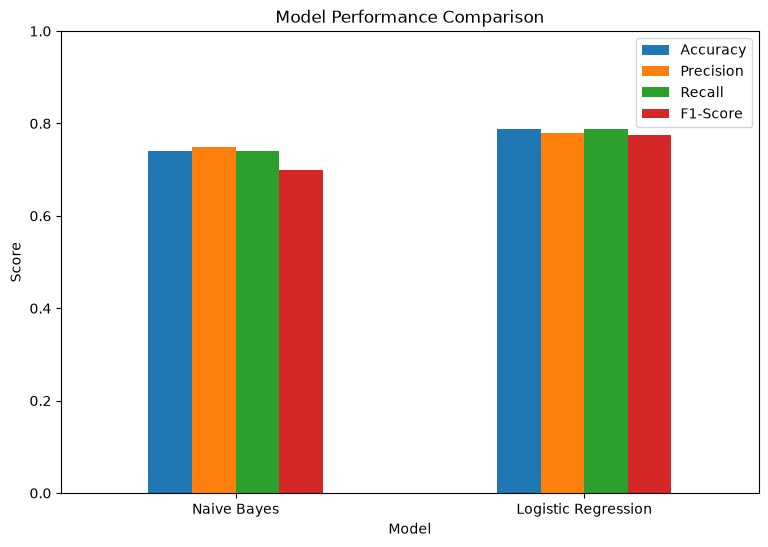

In [31]:
comparison_plot = comparison.copy()

comparison_plot.set_index('Model').plot(
    kind='bar',
    figsize=(9, 6)
)

plt.title("Model Performance Comparison")
plt.xlabel("Model")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.xticks(rotation=0)

plt.show()

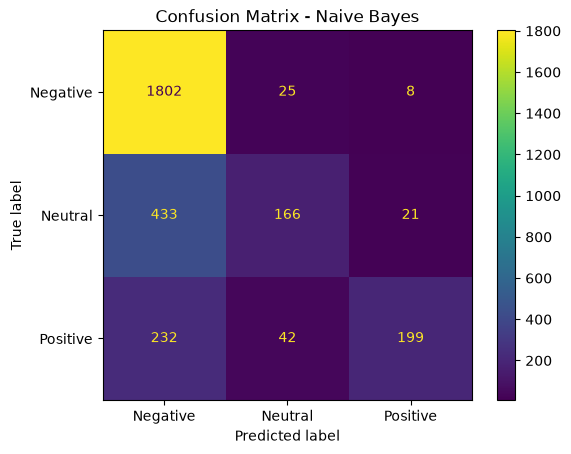

In [32]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

cm_nb = confusion_matrix(
    y_test,
    nb_pred,
    labels=['negative', 'neutral', 'positive']
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_nb,
    display_labels=['Negative', 'Neutral', 'Positive']
)

disp.plot()

plt.title("Confusion Matrix - Naive Bayes")
plt.show()

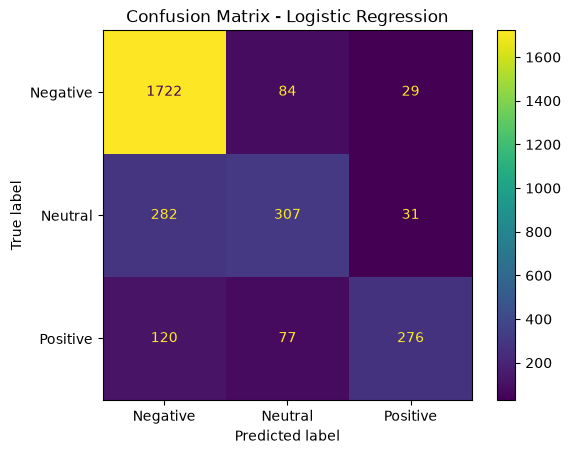

In [33]:
cm_lr = confusion_matrix(
    y_test,
    lr_pred,
    labels=['negative', 'neutral', 'positive']
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_lr,
    display_labels=['Negative', 'Neutral', 'Positive']
)

disp.plot()

plt.title("Confusion Matrix - Logistic Regression")
plt.show()

In [34]:
positive_text = " ".join(
    df[df['sentiment'] == 'positive']['processed_text']
)

positive_wc = WordCloud(
    width=1000,
    height=500,
    background_color='white'
).generate(positive_text)

plt.figure(figsize=(12, 6))
plt.imshow(positive_wc, interpolation='bilinear')
plt.axis('off')
plt.title("Positive Sentiment WordCloud")
plt.show()

NameError: name 'WordCloud' is not defined

In [35]:
from wordcloud import WordCloud

print("WordCloud loaded successfully!")

WordCloud loaded successfully!


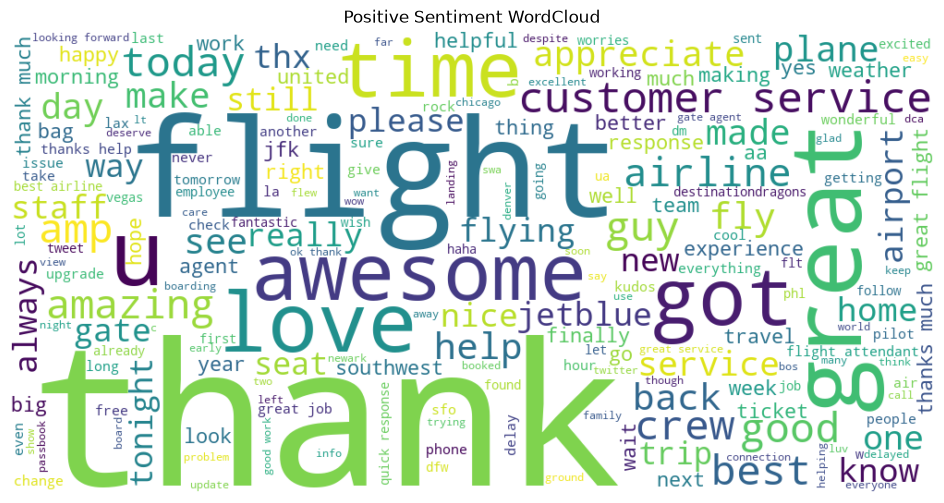

In [36]:
positive_text = " ".join(
    df[df['sentiment'] == 'positive']['processed_text']
)

positive_wc = WordCloud(
    width=1000,
    height=500,
    background_color='white'
).generate(positive_text)

plt.figure(figsize=(12, 6))
plt.imshow(positive_wc, interpolation='bilinear')
plt.axis('off')
plt.title("Positive Sentiment WordCloud")
plt.show()

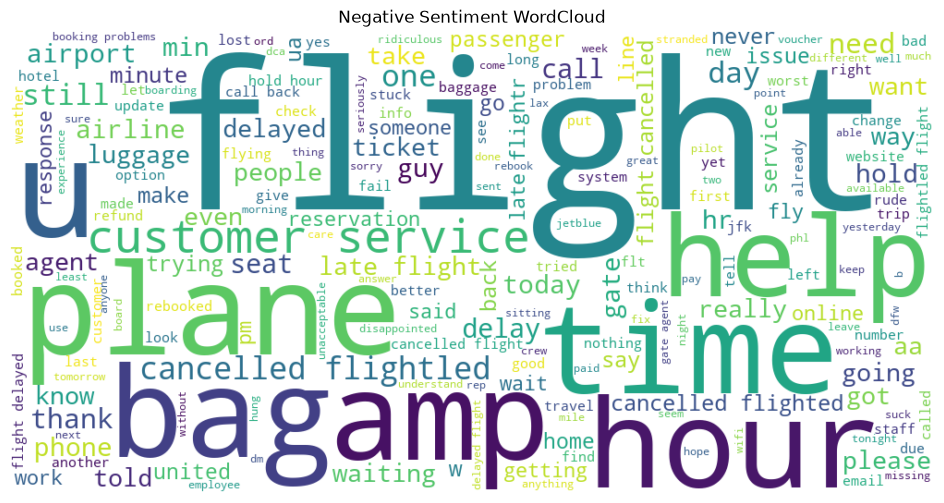

In [37]:
negative_text = " ".join(
    df[df['sentiment'] == 'negative']['processed_text']
)

negative_wc = WordCloud(
    width=1000,
    height=500,
    background_color='white'
).generate(negative_text)

plt.figure(figsize=(12, 6))
plt.imshow(negative_wc, interpolation='bilinear')
plt.axis('off')
plt.title("Negative Sentiment WordCloud")
plt.show()

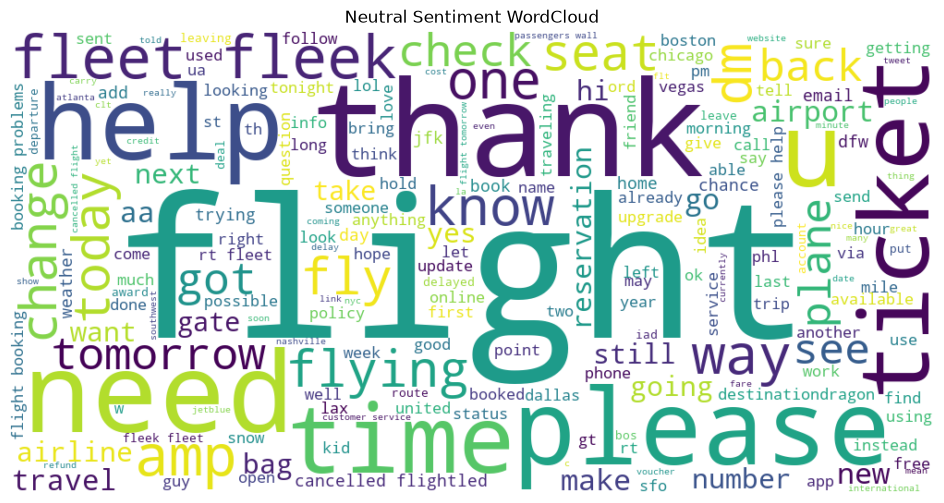

In [38]:
neutral_text = " ".join(
    df[df['sentiment'] == 'neutral']['processed_text']
)

neutral_wc = WordCloud(
    width=1000,
    height=500,
    background_color='white'
).generate(neutral_text)

plt.figure(figsize=(12, 6))
plt.imshow(neutral_wc, interpolation='bilinear')
plt.axis('off')
plt.title("Neutral Sentiment WordCloud")
plt.show()

In [39]:
# Select the better model based on accuracy

if lr_metrics[0] >= nb_metrics[0]:
    best_model_name = "Logistic Regression"
    final_model = lr_model
    best_pred = lr_pred
else:
    best_model_name = "Naive Bayes"
    final_model = nb_model
    best_pred = nb_pred

# Create error analysis DataFrame
error_df = pd.DataFrame({
    'text': X_test.values,
    'actual': y_test.values,
    'predicted': best_pred
})

# Select misclassified tweets
misclassified = error_df[
    error_df['actual'] != error_df['predicted']
]

print("Best Model:", best_model_name)
print("Total Misclassified Tweets:", len(misclassified))

print("\nFive Misclassified Examples:")
display(misclassified.head(5))

Best Model: Logistic Regression
Total Misclassified Tweets: 623

Five Misclassified Examples:


,text,actual,predicted
0,past,neutral,negative
6,link tweet goes someone internal email gt prob...,neutral,negative
9,flight resume see open schedule,negative,neutral
18,well miss gate agents rebooked boarding pass w...,positive,negative
30,site gmail facebook etc,neutral,negative


## Error Analysis

Some tweets were misclassified by the model. This can happen because social media text is informal and sometimes difficult to understand using traditional machine learning techniques.

Possible reasons for incorrect predictions include:

1. **Sarcasm** – The actual meaning may be different from the words used.
2. **Ambiguous language** – A tweet may not clearly express positive or negative sentiment.
3. **Mixed sentiment** – A tweet may contain both positive and negative opinions.
4. **Short tweets** – Very little text may not provide enough information.
5. **Informal language** – Social media contains abbreviations, spelling mistakes and informal expressions.
6. **Context-dependent meaning** – Some tweets require additional context to understand the sentiment.

The five misclassified examples shown above demonstrate cases where the model's predicted sentiment differs from the actual sentiment label.

In [40]:
if lr_metrics[0] >= nb_metrics[0]:
    best_model_name = "Logistic Regression"
    final_model = lr_model
    final_pred = lr_pred
    final_metrics = lr_metrics
else:
    best_model_name = "Naive Bayes"
    final_model = nb_model
    final_pred = nb_pred
    final_metrics = nb_metrics

print("=" * 50)
print("BEST MODEL")
print("=" * 50)
print("Model:", best_model_name)
print("Accuracy:", round(final_metrics[0] * 100, 2), "%")
print("Precision:", round(final_metrics[1] * 100, 2), "%")
print("Recall:", round(final_metrics[2] * 100, 2), "%")
print("F1-Score:", round(final_metrics[3] * 100, 2), "%")

BEST MODEL
Model: Logistic Regression
Accuracy: 78.72 %
Precision: 77.97 %
Recall: 78.72 %
F1-Score: 77.49 %


In [41]:
def predict_sentiment(text):
    processed = preprocess_text(text)
    vector = tfidf.transform([processed])
    prediction = final_model.predict(vector)[0]
    return prediction


test_sentences = [
    "I absolutely love this airline service!",
    "The flight was terrible and very disappointing.",
    "The flight departed at 8 PM."
]

for sentence in test_sentences:
    print("Text:", sentence)
    print("Predicted Sentiment:", predict_sentiment(sentence))
    print("-" * 60)

Text: I absolutely love this airline service!
Predicted Sentiment: positive
------------------------------------------------------------
Text: The flight was terrible and very disappointing.
Predicted Sentiment: negative
------------------------------------------------------------
Text: The flight departed at 8 PM.
Predicted Sentiment: negative
------------------------------------------------------------


# Conclusion

This project developed a machine learning based sentiment analysis system for classifying tweets into three categories:

- Positive
- Negative
- Neutral

The text data was preprocessed using lowercase conversion, URL removal, mention removal, punctuation removal, tokenization and stopword removal.

TF-IDF was used to convert the text data into numerical features that could be processed by machine learning algorithms.

Two machine learning algorithms were trained:

1. Naive Bayes
2. Logistic Regression

Both models were evaluated using:

- Accuracy
- Precision
- Recall
- F1-Score
- Confusion Matrix

Based on the evaluation results, the model with the higher performance was selected as the final model.

## Real-World Applications

Sentiment analysis can be used for:

- Customer feedback analysis
- Airline service feedback
- Social media opinion analysis
- Brand monitoring
- Product review analysis
- Customer satisfaction monitoring

## Limitations

The model may have difficulty understanding:

- Sarcasm
- Mixed opinions
- Spelling mistakes
- Abbreviations
- Context-dependent statements
- Informal social-media language

## Future Scope

The project can be improved in the future by using advanced deep learning and NLP models such as:

- LSTM
- BERT
- Other transformer-based models

In [42]:
import joblib

joblib.dump(final_model, "sentiment_model_final.pkl")
joblib.dump(tfidf, "tfidf_vectorizer_final.pkl")

print("Final model saved successfully!")
print("TF-IDF vectorizer saved successfully!")

Final model saved successfully!
TF-IDF vectorizer saved successfully!


In [43]:
df.to_csv("sentiment_analysis_final_dataset.csv", index=False)

print("Final dataset saved successfully!")

Final dataset saved successfully!


In [44]:
print("=" * 60)
print("       FINAL SENTIMENT ANALYSIS RESULTS")
print("=" * 60)

print("Dataset size:", len(df))

print("\nSentiment Distribution:")
print(df['sentiment'].value_counts())

print("\nBest Model:", best_model_name)

print("Accuracy :", round(final_metrics[0] * 100, 2), "%")
print("Precision:", round(final_metrics[1] * 100, 2), "%")
print("Recall   :", round(final_metrics[2] * 100, 2), "%")
print("F1-Score :", round(final_metrics[3] * 100, 2), "%")

print("=" * 60)

       FINAL SENTIMENT ANALYSIS RESULTS
Dataset size: 14640

Sentiment Distribution:
sentiment
negative    9178
neutral     3099
positive    2363
Name: count, dtype: int64

Best Model: Logistic Regression
Accuracy : 78.72 %
Precision: 77.97 %
Recall   : 78.72 %
F1-Score : 77.49 %


In [45]:
import os

print("PROJECT FILES")
print("=" * 50)

for file in os.listdir():
    print(file)

PROJECT FILES
.git
.ipynb_checkpoints
sentiment_analysis_dataset.csv
sentiment_analysis_final_dataset.csv
Sentiment_Analysis_Project.ipynb
Sentiment_Analysis_Task4_Final.ipynb.ipynb
sentiment_model.pkl
sentiment_model_final.pkl
tfidf_vectorizer.pkl
tfidf_vectorizer_final.pkl
Tweets.csv
Tweets_dataset_folder
